# Notebook 3 — Multimodal Ingestion, Step by Step
## Advanced RAG | Section 3: Tables, Images and Everything Else

**Author:** Suresh D R | AI Product Developer & Technology Mentor

---

Real company knowledge is not clean paragraphs. It is PDFs with tables, charts inside reports, scanned letters, spreadsheets, slides, recordings and code.
In this notebook we take **TechNova's real files** — one at a time — and turn each one into searchable chunks, **comparing different techniques and models** on the same file so you can *see* why each technique exists.

| Part | Guide Section | Data | Techniques / Models Compared |
|---|---|---|---|
| 1 | 3.1 Document Parsing | HR Policy PDF | Basic text extraction **vs** layout-aware parsing |
| 2 | 3.2 Tables | Leave, travel, salary, attrition tables | Strategy 1 label + table · 2 row sentences · 3 summary + full table · 4 SQL + Text-to-SQL |
| 3 | 3.3 Images and Charts | Revenue chart, flowchart | Tesseract OCR **vs** GPT-4o vision · chart → data · diagram → edges · CLIP embeddings |
| 4 | 3.4 Scanned Documents | Scanned offer letter | Tesseract (with clean-up + confidence) **vs** GPT-4o vision |
| 5 | 3.5 Spreadsheets | Joiners CSV | SQL + description + Text-to-SQL |
| 6 | 3.6 Audio | Town hall recording | Whisper transcription with timestamps |
| 7 | 3.7 Code | payments_refunds.py | Syntax-aware splitting + GPT-4o-mini summaries |
| 8 | 3.9 B, C, H | Word, web page, PowerPoint | MarkItDown · raw HTML **vs** trafilatura · slides **without vs with** picture descriptions |
| 9 | 3.8 Unified Pipeline | All of the above | One vector database, one metadata schema, real questions |

### Models Used

| Model | Type | Used For |
|---|---|---|
| **GPT-4o** | Vision + text LLM | Reading charts and scans, Text-to-SQL, final answers |
| **GPT-4o-mini** | Small, cheap LLM | Table labels, table summaries, code summaries |
| **text-embedding-3-small** | Text embedding model | Turning chunks into vectors |
| **Whisper** (`whisper-1`) | Speech-to-text model | Transcribing audio with timestamps |
| **Tesseract** | Classic OCR engine (free, runs locally) | Reading text from images |
| **CLIP** (`clip-ViT-B-32`) | Image + text embedding model | Searching images with text |

> Cells that call an AI model are marked **🤖** in their first line. Every other cell is plain parsing — it runs instantly and costs nothing.

---
### Before You Start: Setup (2 minutes)

**1. The data:** you need `technova_data.zip`. The **Get the Data** cell uploads it (Google Colab) and extracts only `technova_data/multimodal/`.

**2. Your OpenAI API key:**

| Step | What to Do |
|---|---|
| 1 | Go to **platform.openai.com/api-keys** → **Create new secret key** |
| 2 | Copy the key (starts with `sk-`). It is shown **only once** |
| 3 | Make sure your account has **billing / credits** (this notebook costs well under a dollar) |

**3. Give the key to the notebook** — either paste it when the Setup cell asks (hidden box), or add it once in Colab **Secrets** (🔑 icon in the left sidebar) as `OPENAI_API_KEY` with **Notebook access** on.

⚠️ **Never type your key into a code cell.**

In [1]:
%pip install -q openai langchain langchain-openai langchain-community langchain-classic langchain-chroma langchain-text-splitters pymupdf4llm pdfplumber "markitdown[docx,pptx]" trafilatura beautifulsoup4 pytesseract sentence-transformers pandas tabulate pillow sqlalchemy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 645.9 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.4/127.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.4/176.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 MB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 

In [2]:
# Tesseract OCR engine (a system program, not a Python package). Colab does not have it by default.
import shutil, subprocess
if shutil.which("tesseract"):
    print("Tesseract is installed:", subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.splitlines()[0])
else:
    try:
        subprocess.run(["apt-get", "-qq", "install", "-y", "tesseract-ocr"], check=True, capture_output=True)
        print("Tesseract installed.")
    except Exception as e:
        print("Could not install Tesseract automatically. On Colab run:  !apt-get install -y tesseract-ocr\n", e)

Tesseract is installed: tesseract 5.3.4


---
## Get the Data

| Situation | What Happens |
|---|---|
| `technova_data/multimodal/` already exists | Nothing to do |
| `technova_data.zip` is next to the notebook | Extracts only `technova_data/multimodal/` |
| On Google Colab with no zip yet | An upload box opens — choose `technova_data.zip` |

In [3]:
import zipfile
from pathlib import Path

NEEDED = "technova_data/multimodal/"
if Path(NEEDED).exists() and any(Path(NEEDED).iterdir()):
    print("Data folder already available.")
else:
    zips = sorted(Path(".").glob("technova_data*.zip"))
    if zips:
        zip_path = zips[0]
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("Put technova_data.zip next to this notebook, then run this cell again.")
        print("Choose technova_data.zip from your computer:")
        uploaded = files.upload()
        zip_path = Path(next(name for name in uploaded if name.endswith(".zip")))
    with zipfile.ZipFile(zip_path) as z:
        members = [m for m in z.namelist() if m.startswith(NEEDED)]
        z.extractall(".", members=members)
    print(f"Extracted {len(members)} files from {zip_path.name}")

for p in sorted(Path(NEEDED).iterdir()):
    print(f"  {p.name:<34} {p.stat().st_size / 1024:>8.1f} KB")

Extracted 11 files from technova_data.zip
  Annual_Report_2025.pdf                 24.8 KB
  Compensation_Policy_2025.pdf            2.6 KB
  HR_Policy_2025.pdf                      5.0 KB
  Joiners_FY25.csv                        3.1 KB
  Offer_Letter_Scanned.pdf              227.6 KB
  Townhall_FY26.pptx                     52.6 KB
  WFH_Guidelines_2025.docx               36.2 KB
  intranet_leave_faq.html                 0.9 KB
  leave_approval_flow.png                17.9 KB
  payments_refunds.py                     0.7 KB


---
## Setup — Models and Helpers

| Name in Code | Model | Why This One |
|---|---|---|
| `llm` | GPT-4o | Best at reading images; used for vision, SQL and answers |
| `llm_small` | GPT-4o-mini | ~15× cheaper; good enough for short labels and summaries |
| `embeddings` | text-embedding-3-small | Standard, cheap text embeddings |
| `oai` | OpenAI client | Whisper (audio) and MarkItDown's picture descriptions |

`ALL_DOCS` collects every chunk from every file. At the end (Part 9) everything goes into one vector database.

In [4]:
import os, re, json, base64, getpass, sqlite3, warnings
import pandas as pd
from IPython.display import display, Image as ShowImage

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

try:                                                    # Google Colab Secrets (optional)
    from google.colab import userdata
    os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY"))
except Exception:
    pass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("Paste your OpenAI API key: ")

from openai import OpenAI
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage

llm = ChatOpenAI(model="gpt-4o", temperature=0)
llm_small = ChatOpenAI(model="gpt-4o-mini", temperature=0)
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
oai = OpenAI()

DATA = Path("technova_data/multimodal")
OUT = Path("nb3_output"); shutil.rmtree(OUT, ignore_errors=True); (OUT / "images").mkdir(parents=True)
ALL_DOCS = []

def vision(image_bytes, prompt):
    """Ask GPT-4o about an image."""
    b64 = base64.b64encode(image_bytes).decode()
    msg = HumanMessage(content=[{"type": "text", "text": prompt},
                                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64}"}}])
    return llm.invoke([msg]).content.strip()

def show(title, text=""):
    print(f"\n=== {title} ===")
    if text:
        print(text)

def add_docs(docs, what):
    ALL_DOCS.extend(docs)
    print(f"\n+ {len(docs)} chunks added to ALL_DOCS from {what}")

def clean(text):
    return re.sub(r"[*_#]", "", text or "").strip()

print("Ready.")

Paste your OpenAI API key: ··········
Ready.


---
# Part 1 — Document Parsing (Guide 3.1)

**Simple analogy:** before cooking, you sort the groceries. Parsing sorts a page into *heading, paragraph, table, image, header, footer* — so each can be handled the right way.

We read the **same PDF** (`HR_Policy_2025.pdf`) with two techniques and compare.

| Technique | Tool | What It Returns |
|---|---|---|
| **1. Basic text extraction** | PyMuPDF `page.get_text()` | All the characters on the page, in order — nothing else |
| **2. Layout-aware parsing** | `pymupdf4llm.to_markdown()` | Markdown: headings as `#`, tables as tables, images saved, headers and footers removed |

In [5]:
import pymupdf

HR = DATA / "HR_Policy_2025.pdf"
basic = pymupdf.open(HR)[0].get_text()
show("Technique 1 - basic text extraction, page 1", basic)


=== Technique 1 - basic text extraction, page 1 ===
TechNova Solutions Pvt Ltd
Confidential - Page 1
TechNova HR Policy 2025
1. Scope
This policy applies to all full-time employees of TechNova Solutions Pvt Ltd in Bengaluru and
Pune. It is effective from 1 April 2025 and replaces the HR Policy 2024.
Questions about this policy go to your HR Business Partner, Pooja Reddy, or to hr-help on
HRConnect.
2. Working Hours and Work From Home
Standard working hours are 9:30 AM to 6:30 PM, Monday to Friday.
Employees may work from home up to two days per week with manager approval. Details are
in the Work From Home Guidelines 2025.
3. Leave Policy
Employees receive 12 days of paid sick leave per year (increased from 10 days in 2024). A
medical certificate is required for sick leave longer than 2 consecutive days. Unused sick leave
lapses at the end of the year.
Earned leave is 18 days per year and can be carried forward up to a maximum of 45 days.
Casual leave is 6 days per year.
All leave exce

**Look at the output above:**
- The **header** "TechNova Solutions Pvt Ltd" and the **footer** "Confidential - Page 1" are mixed into the text — they would end up inside chunks on every page.
- The **leave table became a list of loose words** (`Earned`, `18`, `Yes, up to 45`, `Sick`, `12`, `No` …). Which "No" belongs to which leave type? This is **Failure 3** in the guide.
- Nothing tells us which lines are **headings**.

In [6]:
import pymupdf4llm

PDFS = {"HR_Policy_2025.pdf": "all_employees",
        "Compensation_Policy_2025.pdf": "hr_leadership",      # confidential
        "Annual_Report_2025.pdf": "all_employees"}
MD_TEXT = {name: pymupdf4llm.to_markdown(str(DATA / name), header=False, footer=False, use_ocr=False,
                                         write_images=True, image_path=str(OUT / "images"))
           for name in PDFS}
show("Technique 2 - layout-aware parsing (pymupdf4llm), HR policy", MD_TEXT["HR_Policy_2025.pdf"])


=== Technique 2 - layout-aware parsing (pymupdf4llm), HR policy ===

![](nb3_output/images/HR_Policy_2025.pdf-0001-01.png)


# **TechNova HR Policy 2025** 

## **1. Scope** 

This policy applies to all full-time employees of TechNova Solutions Pvt Ltd in Bengaluru and Pune. It is effective from 1 April 2025 and replaces the HR Policy 2024. 

Questions about this policy go to your HR Business Partner, Pooja Reddy, or to hr-help on HRConnect. 

## **2. Working Hours and Work From Home** 

Standard working hours are 9:30 AM to 6:30 PM, Monday to Friday. 

Employees may work from home up to two days per week with manager approval. Details are in the Work From Home Guidelines 2025. 

## **3. Leave Policy** 

Employees receive 12 days of paid sick leave per year (increased from 10 days in 2024). A medical certificate is required for sick leave longer than 2 consecutive days. Unused sick leave lapses at the end of the year. 

Earned leave is 18 days per year and can be carried forward up to 

In [ ]:
md = MD_TEXT["HR_Policy_2025.pdf"]
comparison = pd.DataFrame([
    {"check": "Footer 'Confidential - Page' removed", "basic": "Confidential - Page" not in basic, "layout-aware": "Confidential - Page" not in md},
    {"check": "Headings marked",                       "basic": False,                           "layout-aware": "## " in md},
    {"check": "Leave table kept as rows and columns", "basic": "|Earned|18|" in basic.replace(" ", ""),
                                                       "layout-aware": "|Earned|18|" in md.replace(" ", "")},
    {"check": "Images saved separately",               "basic": False,                           "layout-aware": "![](" in md},
])
comparison.replace({True: "YES", False: "no"})

,check,basic,layout-aware
0,Footer 'Confidential - Page' removed,no,YES
1,Headings marked,no,YES
2,Leave table kept as rows and columns,no,YES
3,Images saved separately,no,YES


**Result:** layout-aware parsing wins on every check. From here on, every PDF is read with `pymupdf4llm`.
`use_ocr=False` because these PDFs are *digital* (they have a text layer). Scanned PDFs are handled in Part 4.

---
# Part 2 — Tables (Guide 3.2)

**The problem:** a table is mostly numbers and short words. The salary table never says "salary", so a question about salary may not find it. And embeddings cannot do arithmetic.

First we find **every table** in the three PDFs with **pdfplumber**, which reads the grid lines to get exact rows and columns.

In [7]:
import pdfplumber

TABLES = []
for name, access in PDFS.items():
    with pdfplumber.open(DATA / name) as pdf:
        for pno, page in enumerate(pdf.pages, 1):
            for t in page.find_tables():
                rows = t.extract()
                above = page.crop((0, max(0, t.bbox[1] - 30), page.width, t.bbox[1])).extract_text() or ""
                caption = next((l.strip() for l in above.splitlines() if l.strip().startswith("Table")), "Table")
                TABLES.append({"file": name, "page": pno, "caption": caption, "access": access,
                               "df": pd.DataFrame(rows[1:], columns=rows[0])})

print(f"Found {len(TABLES)} tables")
for t in TABLES:
    show(f"{t['file']} | page {t['page']} | {t['caption']}")
    display(t["df"])

Found 4 tables

=== HR_Policy_2025.pdf | page 1 | Table 1: Leave Entitlement per Year ===


,Leave Type,Days per Year,Carry Forward
0,Earned,18,"Yes, up to 45"
1,Sick,12,No
2,Casual,6,No



=== HR_Policy_2025.pdf | page 2 | Table 2: Domestic Travel Daily Allowance ===


,City Tier,Examples,Hotel Limit (Rs/night),Daily Allowance (Rs)
0,Tier 1,"Mumbai, Delhi, Bengaluru","8,000","2,500"
1,Tier 2,"Pune, Jaipur, Kochi","5,500","1,800"
2,Tier 3,Other cities,"4,000","1,200"



=== Compensation_Policy_2025.pdf | page 1 | Table 4: Salary Bands by Level ===


,Level,Title,Min (Rs),Max (Rs)
0,L1,Associate Engineer,"4,00,000","6,50,000"
1,L2,Engineer,"6,50,000","9,00,000"
2,L3,Senior Engineer,"12,00,000","18,00,000"
3,L4,Lead Engineer,"18,00,000","26,00,000"
4,L5,Engineering Manager,"26,00,000","38,00,000"
5,L6,Senior Manager,"38,00,000","50,00,000"
6,L7,Director,"50,00,000","70,00,000"
7,L8,VP,"70,00,000","1,00,00,000"



=== Annual_Report_2025.pdf | page 2 | Table 5: Attrition by Department FY 2024-25 ===


,Department,Headcount,Attrition (%)
0,Engineering,520,10.4
1,Data & AI,150,14.7
2,Sales,260,14.4
3,HR & Admin,90,9.7
4,Finance,70,8.9
5,Operations,150,8.6
6,Total,"1,240",11.2


### The 4 Table Strategies

| Strategy | What Is Searched (embedded) | What the LLM Reads | Best For |
|---|---|---|---|
| **1. Label + table** | Label on top + the whole table | The same | Small tables |
| **2. One row = one sentence** | One sentence per row | That sentence | Lookups: one row per question |
| **3. Summary + full table** | An LLM-written summary | The **full** table | Large tables, comparisons |
| **4. SQL** | Only a description | The SQL result | Numbers: totals, averages, rankings |

---
## Strategy 1 — Put a Label on Top of Every Table

| Step | Take | From |
|---|---|---|
| 1 | Document name | The `#` title in the Markdown |
| 2 | Section heading | The `##` heading just above the table |
| 3 | Table caption | The line starting with "Table" |
| 4 | One-line meaning | 🤖 GPT-4o-mini writes it |
| 5 | Join them and put them **on top** of the table | — |

In [8]:
def table_markdown(df):
    return ("| " + " | ".join(df.columns) + " |\n|" + "---|" * len(df.columns) + "\n" +
            "\n".join("| " + " | ".join(map(str, r)) + " |" for r in df.values))

def doc_title(name):
    return clean(next(l for l in MD_TEXT[name].splitlines() if l.startswith("# ")))

def section_of(name, caption):
    text = MD_TEXT[name]
    pos = text.find(caption.split(":")[0])
    heads = re.findall(r"^## (.+)$", text[:pos], flags=re.M)
    return clean(heads[-1]) if heads else ""

t = TABLES[0]
steps = {"1. Document name": doc_title(t["file"]), "2. Section heading": section_of(t["file"], t["caption"]),
         "3. Table caption": t["caption"]}
pd.DataFrame(steps.items(), columns=["step", "value"])

,step,value
0,1. Document name,TechNova HR Policy 2025
1,2. Section heading,3. Leave Policy
2,3. Table caption,Table 1: Leave Entitlement per Year


In [9]:
# 🤖 GPT-4o-mini writes the one-line meaning (step 4), then we build the labelled chunk for EVERY table
def meaning_of(t):
    return llm_small.invoke(f"Here is a table from '{doc_title(t['file'])}'.\nCaption: {t['caption']}\n"
                            f"{table_markdown(t['df'])}\n\nWrite ONE short line saying what this table shows.").content.strip()

table_docs = []
for t in TABLES:
    label = (f"Document: {doc_title(t['file'])}\nSection: {section_of(t['file'], t['caption'])}\n"
             f"Table: {t['caption']} - {meaning_of(t)}")
    table_docs.append(Document(page_content=label + "\n\n" + table_markdown(t["df"]),
                               metadata={"source": t["file"], "page": t["page"], "element_type": "table",
                                         "access_level": t["access"]}))
show("Strategy 1 - the stored chunk for the leave table", table_docs[0].page_content)
add_docs(table_docs, "tables (Strategy 1)")


=== Strategy 1 - the stored chunk for the leave table ===
Document: TechNova HR Policy 2025
Section: 3. Leave Policy
Table: Table 1: Leave Entitlement per Year - The table outlines the annual leave entitlements, including the number of days and carry-forward policies for different leave types at TechNova.

| Leave Type | Days per Year | Carry Forward |
|---|---|---|
| Earned | 18 | Yes, up to 45 |
| Sick | 12 | No |
| Casual | 6 | No |

+ 4 chunks added to ALL_DOCS from tables (Strategy 1)


## Strategy 2 — One Row = One Sentence (salary table)

A sentence template turns each row into a self-contained sentence. *"Salary for a Senior Engineer?"* now matches the L3 sentence almost word for word.
These chunks are **confidential** (`access_level: hr_leadership`).

In [10]:
salary = next(t for t in TABLES if t["df"].columns[0] == "Level")["df"]
row_docs = [Document(page_content=f"TechNova Salary Bands 2025 - {r['Title']} ({r['Level']}): "
                                  f"salary from Rs {r['Min (Rs)']} to Rs {r['Max (Rs)']} per year.",
                     metadata={"source": "Compensation_Policy_2025.pdf", "element_type": "table_row",
                               "access_level": "hr_leadership"})
            for _, r in salary.iterrows()]
for d in row_docs:
    print(d.page_content)
add_docs(row_docs, "salary rows (Strategy 2)")

TechNova Salary Bands 2025 - Associate Engineer (L1): salary from Rs 4,00,000 to Rs 6,50,000 per year.
TechNova Salary Bands 2025 - Engineer (L2): salary from Rs 6,50,000 to Rs 9,00,000 per year.
TechNova Salary Bands 2025 - Senior Engineer (L3): salary from Rs 12,00,000 to Rs 18,00,000 per year.
TechNova Salary Bands 2025 - Lead Engineer (L4): salary from Rs 18,00,000 to Rs 26,00,000 per year.
TechNova Salary Bands 2025 - Engineering Manager (L5): salary from Rs 26,00,000 to Rs 38,00,000 per year.
TechNova Salary Bands 2025 - Senior Manager (L6): salary from Rs 38,00,000 to Rs 50,00,000 per year.
TechNova Salary Bands 2025 - Director (L7): salary from Rs 50,00,000 to Rs 70,00,000 per year.
TechNova Salary Bands 2025 - VP (L8): salary from Rs 70,00,000 to Rs 1,00,00,000 per year.

+ 8 chunks added to ALL_DOCS from salary rows (Strategy 2)


## Strategy 3 — Summary for Search, Full Table for the LLM

LangChain's **`MultiVectorRetriever`** stores two things:

| Store | Holds | Used For |
|---|---|---|
| Vector store | 🤖 A 2-sentence **summary** of each table (GPT-4o-mini) | Finding the right table |
| Doc store | The **full** table | What the LLM actually reads |

The question matches the short summary, but the retriever returns the full table.

In [11]:
# 🤖 Summaries by GPT-4o-mini, embedded with text-embedding-3-small
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
from langchain_core.stores import InMemoryStore
from langchain_chroma import Chroma

summary_store = Chroma(collection_name="table_summaries", embedding_function=embeddings)
full_tables = InMemoryStore()
table_retriever = MultiVectorRetriever(vectorstore=summary_store, docstore=full_tables, id_key="table_id")

summaries = []
for i, t in enumerate(TABLES):
    tid = f"table-{i}"
    summary = llm_small.invoke("Summarise this table in 2 sentences with its key facts (highest, lowest, ranges).\n"
                               f"Caption: {t['caption']}\n{table_markdown(t['df'])}").content.strip()
    summaries.append(Document(page_content=summary, metadata={"table_id": tid}))
    full_tables.mset([(tid, Document(page_content=f"{t['caption']}\n{table_markdown(t['df'])}"))])
summary_store.add_documents(summaries)

show("What is embedded (the summaries)")
display(pd.DataFrame([{"table": t["caption"], "summary": s.page_content} for t, s in zip(TABLES, summaries)]))

q = "Which department had the highest attrition?"
result = table_retriever.invoke(q)[0]
show(f"Question: {q}  ->  what the retriever RETURNS (the full table)", result.page_content)


=== What is embedded (the summaries) ===


,table,summary
0,Table 1: Leave Entitlement per Year,"The table outlines leave entitlements per year, with the highest being Earned Leave at 18 days, which can be carried..."
1,Table 2: Domestic Travel Daily Allowance,"The highest daily allowance is Rs 2,500 for Tier 1 cities like Mumbai and Delhi, while the lowest is Rs 1,200 for Ti..."
2,Table 4: Salary Bands by Level,"The salary bands for various levels range from a minimum of Rs 4,00,000 for an Associate Engineer (L1) to a maximum ..."
3,Table 5: Attrition by Department FY 2024-25,"In FY 2024-25, the Data & AI department experienced the highest attrition rate at 14.7%, while the Finance departmen..."



=== Question: Which department had the highest attrition?  ->  what the retriever RETURNS (the full table) ===
Table 5: Attrition by Department FY 2024-25
| Department | Headcount | Attrition (%) |
|---|---|---|
| Engineering | 520 | 10.4 |
| Data & AI | 150 | 14.7 |
| Sales | 260 | 14.4 |
| HR & Admin | 90 | 9.7 |
| Finance | 70 | 8.9 |
| Operations | 150 | 8.6 |
| Total | 1,240 | 11.2 |


## Strategy 4 — SQL for Exact Numbers

| Step | What Happens |
|---|---|
| 1 | Clean each table: `"12,00,000"` → `1200000`, `"14.7"` → `14.7` |
| 2 | Save it as a SQL table (SQLite) |
| 3 | Numbers questions are answered with SQL — exact, every time |

In [12]:
db_path = OUT / "technova.db"
con = sqlite3.connect(db_path)
to_num = lambda s: pd.to_numeric(s.astype(str).str.replace(",", ""), errors="coerce")

sql_tables = {
    "leave_entitlement":    ("Leave Type", {"Leave Type": "leave_type", "Days per Year": "days_per_year", "Carry Forward": "carry_forward"}),
    "travel_allowance":     ("City Tier", {"City Tier": "city_tier", "Examples": "examples", "Hotel Limit (Rs/night)": "hotel_limit_rs",
                                           "Daily Allowance (Rs)": "daily_allowance_rs"}),
    "salary_bands":         ("Level", {"Level": "level", "Title": "title", "Min (Rs)": "min_rs", "Max (Rs)": "max_rs"}),
    "department_attrition": ("Department", {"Department": "department", "Headcount": "headcount", "Attrition (%)": "attrition_pct"}),
}
for table_name, (first_col, columns) in sql_tables.items():
    df = next(t for t in TABLES if t["df"].columns[0] == first_col)["df"].rename(columns=columns)
    for c in df.columns:
        if c.endswith(("_rs", "_pct", "days_per_year", "headcount")):
            df[c] = to_num(df[c])
    df.to_sql(table_name, con, if_exists="replace", index=False)
    print(f"SQL table {table_name:<22} {len(df)} rows")

for title, sql in [("Highest attrition (excluding the Total row)",
                    "SELECT department, attrition_pct FROM department_attrition WHERE department != 'Total' ORDER BY attrition_pct DESC LIMIT 3"),
                   ("Average maximum salary for L1-L5",
                    "SELECT ROUND(AVG(max_rs)) AS avg_max_rs FROM salary_bands WHERE level IN ('L1','L2','L3','L4','L5')"),
                   ("Total leave days per year", "SELECT SUM(days_per_year) AS total_days FROM leave_entitlement")]:
    show(title, "SQL: " + sql)
    display(pd.read_sql_query(sql, con))

SQL table leave_entitlement      3 rows
SQL table travel_allowance       3 rows
SQL table salary_bands           8 rows
SQL table department_attrition   7 rows

=== Highest attrition (excluding the Total row) ===
SQL: SELECT department, attrition_pct FROM department_attrition WHERE department != 'Total' ORDER BY attrition_pct DESC LIMIT 3


,department,attrition_pct
0,Data & AI,14.7
1,Sales,14.4
2,Engineering,10.4



=== Average maximum salary for L1-L5 ===
SQL: SELECT ROUND(AVG(max_rs)) AS avg_max_rs FROM salary_bands WHERE level IN ('L1','L2','L3','L4','L5')


,avg_max_rs
0,1950000.0



=== Total leave days per year ===
SQL: SELECT SUM(days_per_year) AS total_days FROM leave_entitlement


,total_days
0,36


### Text-to-SQL — Ask in English

LangChain's **`create_sql_query_chain`** shows GPT-4o the table schema and asks it to write the SQL. We then run it.

In [13]:
# 🤖 GPT-4o writes the SQL
from langchain_community.utilities import SQLDatabase
from langchain_classic.chains import create_sql_query_chain

sql_db = SQLDatabase.from_uri(f"sqlite:///{db_path}")
sql_chain = create_sql_query_chain(llm, sql_db)

def text_to_sql(question):
    sql = sql_chain.invoke({"question": question})
    sql = re.sub(r"^.*?SQLQuery:\s*|```sql|```", "", sql, flags=re.S).strip()
    return sql, sql_db.run(sql)

for q in ["Which department had the highest attrition rate?", "What is the daily allowance in Pune?"]:
    sql, result = text_to_sql(q)
    show(q, f"SQL:    {sql}\nResult: {result}")


=== Which department had the highest attrition rate? ===
SQL:    SELECT "department", "attrition_pct"
FROM department_attrition
ORDER BY "attrition_pct" DESC
LIMIT 1
Result: [('Data & AI', 14.7)]

=== What is the daily allowance in Pune? ===
SQL:    SELECT "daily_allowance_rs" 
FROM travel_allowance 
WHERE "examples" LIKE '%Pune%'
LIMIT 1
Result: [(1800,)]


| Table Characteristic | Best Strategy |
|---|---|
| Small table, mixed text and numbers (leave, travel) | 1 — Label + table |
| Lookup table, one row per question (salary bands) | 2 — Row sentences |
| Large table, comparison questions | 3 — Summary + full table |
| Numbers, totals, rankings | 4 — SQL |

---
# Part 3 — Images, Charts and Diagrams (Guide 3.3)

**Why:** the Annual Report's text says revenue was Rs 434 crore — but the **quarterly numbers exist only inside the chart picture**.

| Step | What We Do |
|---|---|
| 1 | Find the images `pymupdf4llm` saved; skip tiny ones (logos) |
| 2 | Try **Tesseract OCR** on the chart — see why it is not enough |
| 3 | 🤖 **GPT-4o vision** describes the chart, then extracts its numbers as a table |
| 4 | 🤖 A **flowchart** becomes steps and edges (graph-ready) |
| 5 | 🤖 **CLIP** embeds images and text in the same space (optional) |

,file,width,height,keep
0,Annual_Report_2025.pdf-0001-01.png,51,51,no - logo/icon
1,Annual_Report_2025.pdf-0001-06.png,792,480,yes
2,Annual_Report_2025.pdf-0002-01.png,51,51,no - logo/icon


The chart: Annual_Report_2025.pdf-0001-06.png


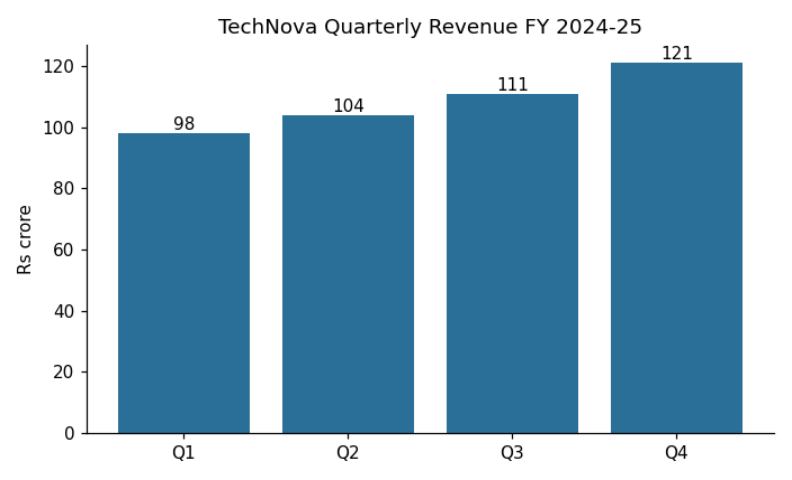

In [14]:
from PIL import Image

images = []
for p in sorted((OUT / "images").glob("Annual_Report*")):
    w, h = Image.open(p).size
    images.append({"file": p.name, "width": w, "height": h, "keep": "yes" if w >= 100 else "no - logo/icon"})
display(pd.DataFrame(images))

CHART = max((OUT / "images").glob("Annual_Report*"), key=lambda p: Image.open(p).size[0] * Image.open(p).size[1])
print("The chart:", CHART.name)
display(ShowImage(filename=str(CHART), width=520))

In [15]:
import pytesseract

chart_ocr = pytesseract.image_to_string(Image.open(CHART))
show("Tesseract OCR on the chart", chart_ocr)


=== Tesseract OCR on the chart ===
Rs crore

120

100

80

60

40

20

TechNova Quarterly Revenue FY 2024-25

121
111
104
i -
Ql Q2 Q3 a4




**Look at the OCR output:** Tesseract reads *characters*, not *meaning*. You get the title and some scattered numbers, but not which number belongs to which quarter, and not the trend. That is why charts need a **vision LLM**.

In [16]:
# 🤖 GPT-4o vision: (a) a description, (b) the chart's data as a table
chart_bytes = CHART.read_bytes()
chart_description = vision(chart_bytes, "This chart is from TechNova's Annual Report FY 2024-25. Describe it: chart type, "
                                        "axes, every value you can read, and the main trend.")
show("GPT-4o - chart description", chart_description)

raw = vision(chart_bytes, 'Extract every data point from this chart. Return only JSON: {"points": [{"label": "...", "value": 0}]}')
try:
    points = json.loads(re.search(r"\{.*\}", raw, flags=re.S).group(0))["points"]
    show("GPT-4o - chart turned into data")
    display(pd.DataFrame(points))
except Exception:
    show("GPT-4o - raw reply (could not parse as JSON)", raw)


=== GPT-4o - chart description ===
The chart is a bar chart titled "TechNova Quarterly Revenue FY 2024-25."

- **X-axis:** Represents the quarters (Q1, Q2, Q3, Q4).
- **Y-axis:** Represents revenue in Rs crore, ranging from 0 to 120.

**Values:**
- Q1: 98 crore
- Q2: 104 crore
- Q3: 111 crore
- Q4: 121 crore

**Main Trend:**
The revenue shows a consistent upward trend across the quarters, increasing from Q1 to Q4.

=== GPT-4o - chart turned into data ===


,label,value
0,Q1,98
1,Q2,104
2,Q3,111
3,Q4,121


In [17]:
# The description replaces the image link, so the chart's numbers become searchable text
def describe_images(md):
    md = re.sub(r"<!-- Start of picture text -->.*?<!-- End of picture text -->", "", md, flags=re.S)
    def replace(m):
        path = Path(m.group(1))
        if Image.open(path).width < 100:
            return ""                                            # logo
        return f"[Chart description: {chart_description}]" if path == CHART else ""
    return re.sub(r"!\[[^\]]*\]\(([^)]+)\)", replace, md)

MD_TEXT["Annual_Report_2025.pdf"] = describe_images(MD_TEXT["Annual_Report_2025.pdf"])
for name in ["HR_Policy_2025.pdf", "Compensation_Policy_2025.pdf"]:
    MD_TEXT[name] = describe_images(MD_TEXT[name])                # only removes the logos
show("Annual Report after adding the description", MD_TEXT["Annual_Report_2025.pdf"][:1400])


=== Annual Report after adding the description ===




# **TechNova Annual Report FY 2024-25** 

## **1. Financial Highlights** 

TechNova's revenue for FY 2024-25 was Rs 434 crore, up 18% from the previous year, with an EBITDA margin of 20.2%. 

Growth came mainly from enterprise payments customers and the analytics business. 


[Chart description: The chart is a bar chart titled "TechNova Quarterly Revenue FY 2024-25."

- **X-axis:** Represents the quarters (Q1, Q2, Q3, Q4).
- **Y-axis:** Represents revenue in Rs crore, ranging from 0 to 120.

**Values:**
- Q1: 98 crore
- Q2: 104 crore
- Q3: 111 crore
- Q4: 121 crore

**Main Trend:**
The revenue shows a consistent upward trend across the quarters, increasing from Q1 to Q4.]


_Figure 3: Quarterly Revenue FY 2024-25 (Rs crore)_ 





## **2. People** 

TechNova ended the year with 1,240 employees: 860 in Bengaluru and 380 in Pune. 

Overall attrition was 11.2%. Attrition was highest in Data & AI and Sales, where competitor offers wer

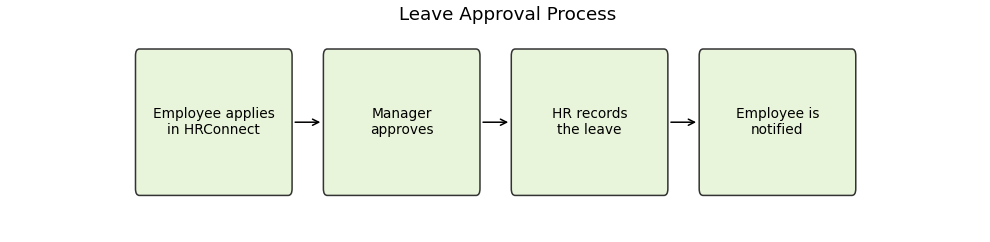


=== Steps ===
Employee applies in HRConnect -> Manager approves -> HR records the leave -> Employee is notified


,from,to
0,Employee applies in HRConnect,Manager approves
1,Manager approves,HR records the leave
2,HR records the leave,Employee is notified



+ 1 chunks added to ALL_DOCS from the flowchart image


In [18]:
# 🤖 Diagram -> steps and edges (the edges could be loaded straight into a graph, Notebook 1)
flow_png = (DATA / "leave_approval_flow.png").read_bytes()
display(ShowImage(data=flow_png, width=620))
raw = vision(flow_png, 'This is a flowchart. Return only JSON: {"steps": ["..."], "edges": [["from step", "to step"]]}')
try:
    flow = json.loads(re.search(r"\{.*\}", raw, flags=re.S).group(0))
    show("Steps", " -> ".join(flow["steps"]))
    display(pd.DataFrame(flow["edges"], columns=["from", "to"]))
    flow_text = "Leave approval process (flowchart): " + " -> ".join(flow["steps"])
except Exception:
    flow_text = "Leave approval process (flowchart): " + raw
    show("Raw reply", raw)
flow_doc = Document(page_content=flow_text, metadata={"source": "leave_approval_flow.png", "element_type": "diagram",
                                                      "access_level": "all_employees"})
add_docs([flow_doc], "the flowchart image")

### Approach 2 — Multimodal Embeddings With CLIP (optional)

**CLIP** puts images and text in the **same vector space**. A photo of a bar chart and the words "a bar chart" land close together — no caption needed.
The cell downloads the CLIP model (~600 MB) the first time. Look at which image each text query is closest to.

*Approach 3, page-image retrieval (ColPali), needs a GPU and is not run here — see Guide 3.3.*

In [19]:
# 🤖 CLIP image + text embeddings (open-source model, runs on your machine / Colab)
try:
    from sentence_transformers import SentenceTransformer, util
    clip = SentenceTransformer("clip-ViT-B-32")
    pictures = {"revenue chart": CHART, "leave flowchart": DATA / "leave_approval_flow.png"}
    img_vecs = clip.encode([Image.open(p).convert("RGB") for p in pictures.values()], convert_to_tensor=True)
    queries = ["a bar chart of company revenue", "a process diagram with boxes and arrows", "a photo of people in an office"]
    txt_vecs = clip.encode(queries, convert_to_tensor=True)
    sims = util.cos_sim(txt_vecs, img_vecs).cpu().numpy().round(3)
    display(pd.DataFrame(sims, index=queries, columns=list(pictures)))
except Exception as e:
    print("CLIP step skipped:", type(e).__name__, e)

CLIP step skipped: ImportError cannot import name '_Ink' from 'PIL._typing' (/usr/local/lib/python3.13/dist-packages/PIL/_typing.py)


In [20]:
# Now chunk the three PDFs by section (tables were already stored in Part 2, so we remove them from the text)
from langchain_text_splitters import MarkdownHeaderTextSplitter
splitter = MarkdownHeaderTextSplitter(headers_to_split_on=[("#", "title"), ("##", "section")])

def md_to_docs(md, source, access, element_type="text"):
    md = re.sub(r"^\|.*\|\s*$\n?", "", md, flags=re.M)                  # table rows
    md = re.sub(r"^_?Table \d+:.*$\n?", "", md, flags=re.M)             # table captions
    docs = []
    for d in splitter.split_text(md):
        body = d.page_content.strip()
        if body:
            docs.append(Document(page_content=f"Document: {clean(d.metadata.get('title'))} | "
                                              f"Section: {clean(d.metadata.get('section'))}\n{body}",
                                 metadata={"source": source, "section": clean(d.metadata.get("section")),
                                           "element_type": element_type, "access_level": access}))
    return docs

pdf_docs = [d for name, access in PDFS.items() for d in md_to_docs(MD_TEXT[name], name, access)]
display(pd.DataFrame([{"source": d.metadata["source"], "section": d.metadata["section"],
                       "chunk": d.page_content.split("\n", 1)[1][:90]} for d in pdf_docs]))
add_docs(pdf_docs, "PDF text sections")

,source,section,chunk
0,HR_Policy_2025.pdf,1. Scope,This policy applies to all full-time employees of TechNova Solutions Pvt Ltd in Bengaluru
1,HR_Policy_2025.pdf,2. Working Hours and Work From Home,"Standard working hours are 9:30 AM to 6:30 PM, Monday to Friday. \nEmployees may work from"
2,HR_Policy_2025.pdf,3. Leave Policy,Employees receive 12 days of paid sick leave per year (increased from 10 days in 2024). A
3,HR_Policy_2025.pdf,4. Parental Leave,"Maternity leave is 26 weeks, fully paid. Employees are eligible after 80 days of service i"
4,HR_Policy_2025.pdf,5. Travel and Expenses,"Expense claims above Rs 50,000 need approval from the department head. Claims must be subm"
5,HR_Policy_2025.pdf,6. Code of Conduct and Grievances,Employees must treat colleagues and customers with respect. Harassment of any kind is not
6,Compensation_Policy_2025.pdf,1. Salary Structure,Every role at TechNova is mapped to a level. Each level has a yearly salary range.
7,Compensation_Policy_2025.pdf,2. Bonus,The annual performance bonus ranges from 0% to 20% of fixed pay.
8,Annual_Report_2025.pdf,1. Financial Highlights,"TechNova's revenue for FY 2024-25 was Rs 434 crore, up 18% from the previous year, with an"
9,Annual_Report_2025.pdf,2. People,"TechNova ended the year with 1,240 employees: 860 in Bengaluru and 380 in Pune. \nOverall"



+ 11 chunks added to ALL_DOCS from PDF text sections


---
# Part 4 — Scanned Documents and OCR (Guide 3.4)

`Offer_Letter_Scanned.pdf` is a **picture** of a letter — slightly tilted, with scanner speckles, and **no text layer**.

| Technique | Model | Strengths | Weaknesses |
|---|---|---|---|
| **A. Tesseract** + image clean-up | Classic OCR engine (free, local) | Fast, free, gives a **confidence score** per word | Struggles with noise, tilt, handwriting, complex layouts |
| **B. GPT-4o vision** | Vision LLM | Reads messy scans in context | Costs money, can occasionally "correct" what it sees |

Text layer on the page: ''  -> empty, so this is a scan


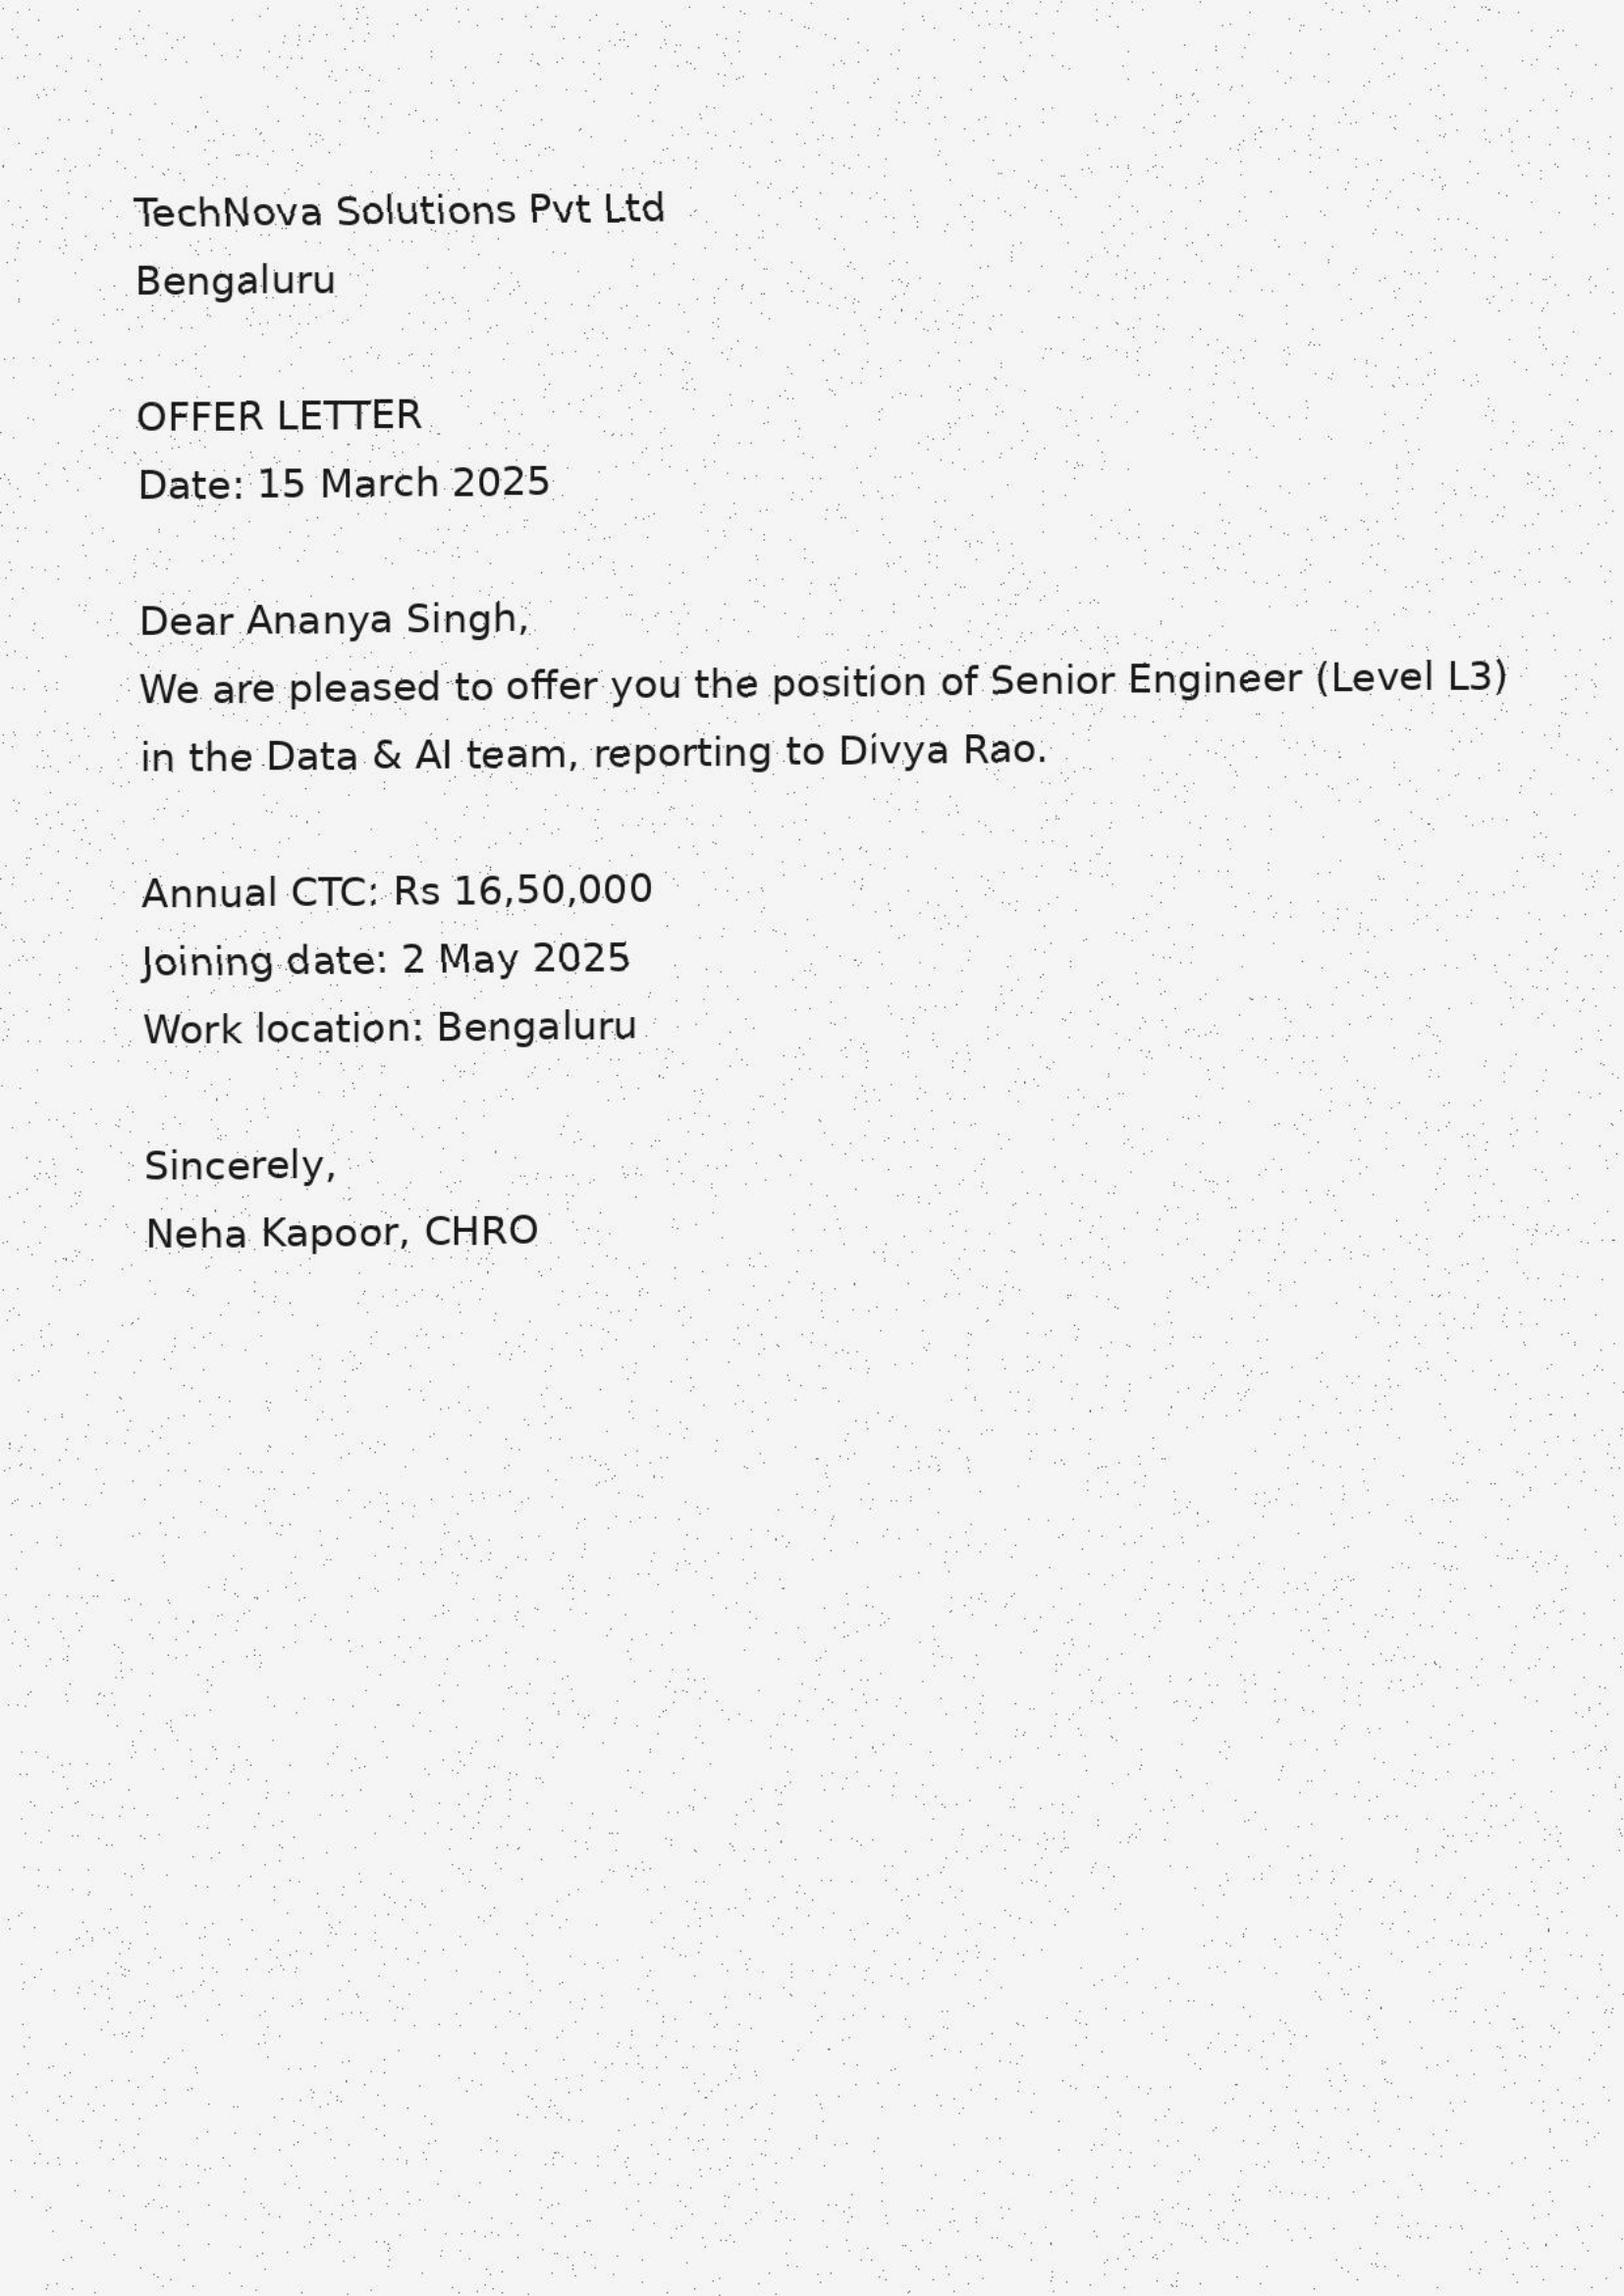

In [21]:
SCAN = DATA / "Offer_Letter_Scanned.pdf"
page = pymupdf.open(SCAN)[0]
print("Text layer on the page:", repr(page.get_text()), " -> empty, so this is a scan")

page_png = page.get_pixmap(dpi=200).tobytes("png")
(OUT / "offer_letter_page.png").write_bytes(page_png)
display(ShowImage(data=page_png, width=430))

### Technique A — Tesseract, With Image Clean-Up

| Step | What It Does | Why |
|---|---|---|
| 1 | Convert to **grayscale** | Colour adds nothing for text |
| 2 | **Auto-contrast** | Makes faint text darker |
| 3 | **Binarise** (every pixel → black or white) | Removes grey speckles from the scanner |
| 4 | `image_to_data` | Text **and** a confidence score (0–100) for every word |

In [22]:
from PIL import ImageOps

img = Image.open(OUT / "offer_letter_page.png").convert("L")        # 1. grayscale
img = ImageOps.autocontrast(img)                                     # 2. contrast
clean_img = img.point(lambda x: 255 if x > 150 else 0)              # 3. black and white

tess_text = pytesseract.image_to_string(clean_img)
words = pytesseract.image_to_data(clean_img, output_type=pytesseract.Output.DATAFRAME)
words = words[(words.conf > 0) & words.text.astype(str).str.strip().ne("")]
ocr_confidence = round(float(words.conf.mean()), 1)

show("Tesseract text", tess_text.strip())
print(f"\nAverage word confidence: {ocr_confidence}")
show("The 8 least confident words (check these!)")
display(words.sort_values("conf")[["text", "conf"]].head(8))


=== Tesseract text ===
TechNova Solutions Pvt Ltd

Bengaluru

OFFER LETTER
Date: 15 March 2025

Dear Ananya Singh,
We are pleased to offer you the position of Senior Engineer (Level L3)

in the Data.& Al team, reporting to Divya Rao.

Annual CTC: Rs 16,50,000
Joining date: 2 May 2025

Work location: Bengaluru

Sincerely,
Neha Kapoor, CHRO

Average word confidence: 92.5

=== The 8 least confident words (check these!) ===


,text,conf
6,Pvt,55.719803
47,Data.&,61.670128
64,2,67.964241
46,the,73.993263
65,May,86.790016
31,pleased,87.157272
32,to,87.157272
18,Date:,89.261665


In [23]:
# 🤖 Technique B - GPT-4o vision
vision_text = vision(page_png, "Transcribe all the text in this scanned letter exactly, line by line. Do not add anything.")
show("GPT-4o vision text", vision_text)


=== GPT-4o vision text ===
TechNova Solutions Pvt Ltd  
Bengaluru  

OFFER LETTER  
Date: 15 March 2025  

Dear Ananya Singh,  
We are pleased to offer you the position of Senior Engineer (Level L3)  
in the Data & AI team, reporting to Divya Rao.  

Annual CTC: Rs 16,50,000  
Joining date: 2 May 2025  
Work location: Bengaluru  

Sincerely,  
Neha Kapoor, CHRO


In [24]:
# Compare the key facts, fix typical number errors (letter O read as zero), and store the result
def fix_numbers(text):
    return re.sub(r"(?<=\d)[Oo](?=[\d,])|(?<=[\d,])[Oo](?=\d)", "0", text)

facts = {"Candidate": r"Dear ([A-Z][a-z]+ [A-Z][a-z]+)", "Level": r"Level (L\d)",
         "CTC": r"CTC:?\s*Rs\.?\s*([\d,Oo]+)", "Joining date": r"Joining\.? date:?\s*([0-9]+ \w+ \d{4})",
         "Reports to": r"reporting to ([A-Z][a-z]+ [A-Z][a-z]+)"}
grab = lambda text, pat: (re.search(pat, text) or [None, "-"])[1]
display(pd.DataFrame([{"fact": f, "Tesseract": grab(tess_text, p), "GPT-4o vision": grab(vision_text, p)}
                      for f, p in facts.items()]))

final_text = fix_numbers(vision_text if len(vision_text) > 50 else tess_text)
scan_doc = Document(page_content=f"Document: Offer Letter (scanned) - Ananya Singh\n{final_text}",
                    metadata={"source": SCAN.name, "element_type": "ocr_text", "ocr_confidence": ocr_confidence,
                              "access_level": "hr_leadership"})
add_docs([scan_doc], "the scanned offer letter")

,fact,Tesseract,GPT-4o vision
0,Candidate,Ananya Singh,Ananya Singh
1,Level,L3,L3
2,CTC,"16,50,000","16,50,000"
3,Joining date,2 May 2025,2 May 2025
4,Reports to,Divya Rao,Divya Rao



+ 1 chunks added to ALL_DOCS from the scanned offer letter


**Store the confidence:** `ocr_confidence` is saved in the metadata. In production, chunks with low confidence are flagged, so the LLM does not quote a misread number as fact.

---
# Part 5 — Spreadsheets and CSV (Guide 3.5)

**Simple analogy:** a spreadsheet is a database that forgot it was one. Let it be a database again.

| Step | What Happens |
|---|---|
| 1 | Load the CSV into SQL |
| 2 | Store only a **description** of the table in the vector database (60 near-identical rows would make search useless) |
| 3 | Number questions → 🤖 Text-to-SQL |

In [25]:
joiners = pd.read_csv(DATA / "Joiners_FY25.csv")
joiners.to_sql("joiners_fy25", con, if_exists="replace", index=False)
display(joiners.head())

description = (f"Spreadsheet Joiners_FY25.csv (SQL table joiners_fy25): one row per employee who joined TechNova in FY 2024-25 "
               f"({joiners.join_date.min()} to {joiners.join_date.max()}). {len(joiners)} rows. Columns: {', '.join(joiners.columns)}. "
               f"Departments: {', '.join(sorted(joiners.department.unique()))}.")
show("What goes into the vector database (description only)", description)
add_docs([Document(page_content=description, metadata={"source": "Joiners_FY25.csv", "element_type": "sql_table",
                                                       "access_level": "all_employees"})], "the CSV")

show("SQL: joiners per department")
display(pd.read_sql_query("SELECT department, COUNT(*) AS joiners FROM joiners_fy25 GROUP BY department ORDER BY joiners DESC", con))

,emp_id,name,department,level,join_date,location
0,EMP1000,Diya Rao,Data & AI,L1,2024-04-04,Pune
1,EMP1001,Sara Gupta,Sales,L2,2024-04-14,Pune
2,EMP1002,Ananya Das,Sales,L2,2024-04-17,Bengaluru
3,EMP1003,Diya Menon,Data & AI,L2,2024-05-04,Bengaluru
4,EMP1004,Ishaan Sharma,HR & Admin,L1,2024-05-10,Pune



=== What goes into the vector database (description only) ===
Spreadsheet Joiners_FY25.csv (SQL table joiners_fy25): one row per employee who joined TechNova in FY 2024-25 (2024-04-04 to 2025-03-29). 60 rows. Columns: emp_id, name, department, level, join_date, location. Departments: Data & AI, Engineering, Finance, HR & Admin, Sales.

+ 1 chunks added to ALL_DOCS from the CSV

=== SQL: joiners per department ===


,department,joiners
0,Engineering,20
1,Data & AI,18
2,HR & Admin,9
3,Sales,8
4,Finance,5


In [27]:
# 🤖 Text-to-SQL on the joiners table
sql_db = SQLDatabase.from_uri(f"sqlite:///{db_path}")
sql_chain = create_sql_query_chain(llm, sql_db)

def text_to_sql(question):
    raw = sql_chain.invoke({"question": question})
    raw = raw.split("SQLQuery:")[-1]                                  # drop any text before the query
    raw = re.sub(r"```(?:sql)?", "", raw)                             # drop code fences
    sql = raw.strip().split("\n\n")[0]                                # stop at the first blank line
    sql = re.split(r"\b(?:SQLResult|Answer|Assuming)\b", sql)[0]      # drop explanation after the query
    sql = sql.strip().split(";")[0].strip()                           # keep only one statement
    return sql, sql_db.run(sql)

for q in ["How many people joined between October and December 2024? (join_date is text YYYY-MM-DD)",
          "How many L3 engineers joined in Bengaluru?"]:
    sql, result = text_to_sql(q)
    show(q, f"SQL:    {sql}\nResult: {result}")


=== How many people joined between October and December 2024? (join_date is text YYYY-MM-DD) ===
SQL:    SELECT COUNT("emp_id") FROM joiners_fy25 WHERE "join_date" BETWEEN '2024-10-01' AND '2024-12-31'
Result: [(15,)]

=== How many L3 engineers joined in Bengaluru? ===
SQL:    SELECT COUNT("emp_id") FROM joiners_fy25 WHERE "level" = 'L3' AND "location" = 'Bengaluru'
Result: [(6,)]


---
# Part 6 — Audio (Guide 3.6)

**Simple analogy:** you cannot search a recording by listening to all of it — but a transcript with timestamps is like a book with page numbers.

| Step | What Happens | Model |
|---|---|---|
| 1 | Transcribe with **segment timestamps** | 🤖 Whisper (`whisper-1`, `verbose_json`) |
| 2 | Add the **speaker** (each file is one speaker here; for mixed recordings use a diarisation tool) | — |
| 3 | 2 segments = 1 chunk, with `start` in the metadata | — |

The audio files are created by Notebook 0 with an OpenAI key. If they are missing, this part is skipped.

In [29]:
# 🤖 Create the two town-hall audio files (OpenAI text-to-speech) if they are missing
AUDIO_SCRIPT = {
    "townhall_part1.mp3": ("onyx", "Good morning everyone. Our FY26 hiring target is 400 people. "
                                   "Most of the new roles are in Engineering and Data and AI."),
    "townhall_part2.mp3": ("nova", "Thank you Arjun. From April, sick leave increases from 10 to 12 days. "
                                   "Please apply for all leave through HRConnect."),
}
for name, (voice, text) in AUDIO_SCRIPT.items():
    path = DATA / name
    if path.exists():
        print(f"{name} already exists")
        continue
    audio = oai.audio.speech.create(model="tts-1", voice=voice, input=text)
    path.write_bytes(audio.content)
    print(f"Created {name} ({path.stat().st_size / 1024:.1f} KB)")

Created townhall_part1.mp3 (125.2 KB)
Created townhall_part2.mp3 (122.2 KB)


In [30]:
# 🤖 Whisper speech-to-text
SPEAKERS = {"townhall_part1.mp3": "Arjun Mehta (CEO)", "townhall_part2.mp3": "Neha Kapoor (CHRO)"}
ts = lambda s: f"{int(s) // 60:02d}:{int(s) % 60:02d}"
get = lambda s, k: s[k] if isinstance(s, dict) else getattr(s, k)

audio_docs, segments_table, offset = [], [], 0.0
for name, speaker in SPEAKERS.items():
    if not (DATA / name).exists():
        print(f"{name} not found - skipped")
        continue
    with open(DATA / name, "rb") as f:
        tr = oai.audio.transcriptions.create(model="whisper-1", file=f, response_format="verbose_json",
                                             timestamp_granularities=["segment"])
    segs = [(get(s, "start") + offset, get(s, "end") + offset, get(s, "text").strip()) for s in tr.segments]
    segments_table += [{"start": ts(a), "end": ts(b), "speaker": speaker, "text": t} for a, b, t in segs]
    for i in range(0, len(segs), 2):
        g = segs[i:i + 2]
        audio_docs.append(Document(
            page_content=f"Town hall recording [{ts(g[0][0])}-{ts(g[-1][1])}] {speaker}: " + " ".join(t for _, _, t in g),
            metadata={"source": name, "element_type": "transcript", "speaker": speaker, "start": ts(g[0][0]),
                      "access_level": "all_employees"}))
    offset = segs[-1][1] if segs else offset
if segments_table:
    display(pd.DataFrame(segments_table))
    add_docs(audio_docs, "the town hall audio")

,start,end,speaker,text
0,00:00,00:01,Arjun Mehta (CEO),"Good morning, everyone."
1,00:01,00:04,Arjun Mehta (CEO),Our FY26 hiring target is 400 people.
2,00:04,00:08,Arjun Mehta (CEO),Most of the new roles are in engineering and data and AI.
3,00:08,00:10,Neha Kapoor (CHRO),"Thank you, Arjun."
4,00:10,00:13,Neha Kapoor (CHRO),"From April, sick leave increases from 10 to 12 days."
5,00:13,00:17,Neha Kapoor (CHRO),Please apply for all leave through HR Connect.



+ 4 chunks added to ALL_DOCS from the town hall audio


---
# Part 7 — Code (Guide 3.7)

**Simple analogy:** you would never cut a recipe in the middle of step 3. A function cut in half is meaningless.

| Step | What Happens | Tool / Model |
|---|---|---|
| 1 | Split on Python syntax — every function stays whole | `RecursiveCharacterTextSplitter.from_language(Language.PYTHON)` |
| 2 | Write a plain-English summary of each function | 🤖 GPT-4o-mini |
| 3 | Chunk = summary **+** code — English questions find it, the LLM still sees the code | — |

In [31]:
from langchain_text_splitters import RecursiveCharacterTextSplitter, Language

code = (DATA / "payments_refunds.py").read_text()
pieces = [p for p in RecursiveCharacterTextSplitter.from_language(Language.PYTHON, chunk_size=400, chunk_overlap=0)
          .split_text(code) if "def " in p]
for p in pieces:
    show(re.search(r"def (\w+)", p).group(1), p)


=== calculate_refund ===
from datetime import date, timedelta


def calculate_refund(amount, gateway_fee_pct=2.0):
    """Return the refund after deducting the payment gateway fee."""
    fee = round(amount * gateway_fee_pct / 100, 2)
    return round(amount - fee, 2)

=== is_refund_eligible ===
def is_refund_eligible(payment_date, today=None, window_days=30):
    today = today or date.today()
    return today - payment_date <= timedelta(days=window_days)

=== process_failed_payment ===
def process_failed_payment(payment):
    if payment["status"] != "FAILED":
        return None
    if not is_refund_eligible(payment["date"]):
        return {"refund": 0, "reason": "outside 30-day window"}
    return {"refund": calculate_refund(payment["amount"]), "reason": "failed payment"}


In [32]:
# 🤖 GPT-4o-mini summaries
code_docs = []
for p in pieces:
    name = re.search(r"def (\w+)", p).group(1)
    summary = llm_small.invoke(f"In 2 sentences, explain in plain English what this Python code does:\n{p}").content.strip()
    code_docs.append(Document(page_content=f"File: payments_refunds.py | Function: {name}\nSummary: {summary}\n\n{p}",
                              metadata={"source": "payments_refunds.py", "element_type": "code", "access_level": "all_employees"}))
display(pd.DataFrame([{"function": re.search(r"Function: (\w+)", d.page_content).group(1),
                       "summary": d.page_content.split("Summary: ")[1].split("\n")[0]} for d in code_docs]))
add_docs(code_docs, "the code file")

,function,summary
0,calculate_refund,This Python code defines a function that calculates the amount of money a person will receive as a refund after subt...
1,is_refund_eligible,This Python code defines a function that checks if a payment is eligible for a refund based on the date it was made....
2,process_failed_payment,"This Python code checks if a payment has failed; if it hasn't, it does nothing. If the payment has failed but is not..."



+ 3 chunks added to ALL_DOCS from the code file


---
# Part 8 — Word, Web Page and PowerPoint (Guide 3.9 B, C, H)

## B. Word Document — MarkItDown

A `.docx` file is already structured (headings, paragraphs, tables). **MarkItDown** converts it straight to Markdown.

In [33]:
from markitdown import MarkItDown

plain_mid = MarkItDown()                                   # no LLM
docx_md = plain_mid.convert(str(DATA / "WFH_Guidelines_2025.docx")).text_content
show("MarkItDown output", docx_md)

docx_md = "# TechNova Work From Home Guidelines 2025\n" + re.sub(r"^# ", "## ", docx_md, flags=re.M)
splitter_keep_tables = MarkdownHeaderTextSplitter(headers_to_split_on=[("#", "title"), ("##", "section")])
word_docs = [Document(page_content=f"Document: TechNova Work From Home Guidelines 2025 | Section: {d.metadata.get('section', '')}\n"
                                   f"{d.page_content.strip()}",
                      metadata={"source": "WFH_Guidelines_2025.docx", "element_type": "text", "access_level": "all_employees"})
             for d in splitter_keep_tables.split_text(docx_md) if d.page_content.strip()]
add_docs(word_docs, "the Word document")


=== MarkItDown output ===
TechNova Work From Home Guidelines 2025

# 1. Eligibility

All full-time employees who have completed their probation can work from home up to two days per week with manager approval.

# 2. Equipment

TechNova provides the equipment below for home working.

Table 2: Home Office Equipment Allowance

|  |  |
| --- | --- |
| Item | Allowance |
| Laptop | Provided by IT |
| Monitor | Rs 10,000 one-time |
| Internet | Rs 1,500 per month |

# 3. Security

Always connect through the company VPN. Never work on confidential files from public Wi-Fi.

+ 4 chunks added to ALL_DOCS from the Word document


## C. Web Page — Raw HTML Text vs `trafilatura`

| Technique | What You Get |
|---|---|
| **Raw text** (BeautifulSoup `get_text()`) | Everything on the page — menus, cookie banner, ads, footer, script |
| **trafilatura** | Only the main article, as Markdown, tables kept |

In [34]:
from bs4 import BeautifulSoup
import trafilatura

html = (DATA / "intranet_leave_faq.html").read_text()
raw_text = " ".join(BeautifulSoup(html, "html.parser").get_text(" ").split())
main_md = trafilatura.extract(html, output_format="markdown", include_tables=True)

show("Technique 1 - raw HTML text (noise included)", raw_text)
show("Technique 2 - trafilatura (main content only)", main_md)
noise = ["Home | HR | IT", "cookies", "Goa trip", "Copyright"]
display(pd.DataFrame([{"noise": n, "in raw text": n in raw_text, "in trafilatura": n in main_md} for n in noise])
        .replace({True: "YES", False: "no"}))

web_docs = [Document(page_content=f"Document: Leave FAQ (HR Intranet) | Section: {part.splitlines()[0].strip('# ')}\n"
                                  + "\n".join(part.splitlines()[1:]).strip(),
                     metadata={"source": "intranet_leave_faq.html", "element_type": "web", "access_level": "all_employees"})
            for part in re.split(r"\n(?=## )", main_md) if part.startswith("## ")]
add_docs(web_docs, "the web page")


=== Technique 1 - raw HTML text (noise included) ===
Leave FAQ - HR Intranet Home | HR | IT | Finance | Login We use cookies. Accept all? Book your Goa trip with 20% off! Leave FAQ Can I cancel approved leave? Yes. Cancel it in HRConnect at least one day before the leave starts. The days are returned to your balance. What are the public holidays in Bengaluru? Date Holiday 15 Aug 2025 Independence Day 2 Oct 2025 Gandhi Jayanti 1 Nov 2025 Karnataka Rajyotsava Copyright TechNova Solutions. All rights reserved.

=== Technique 2 - trafilatura (main content only) ===
# Leave FAQ

## Can I cancel approved leave?

Yes. Cancel it in HRConnect at least one day before the leave starts. The days are returned to your balance.

## What are the public holidays in Bengaluru?

| Date | Holiday | 
|---|---|
| 15 Aug 2025 | Independence Day | 
| 2 Oct 2025 | Gandhi Jayanti | 
| 1 Nov 2025 | Karnataka Rajyotsava |


,noise,in raw text,in trafilatura
0,Home | HR | IT,YES,no
1,cookies,YES,no
2,Goa trip,YES,no
3,Copyright,YES,no



+ 2 chunks added to ALL_DOCS from the web page


## H. PowerPoint — Without vs With Picture Descriptions

MarkItDown reads every slide's text **and speaker notes**. Slide 3 is only a chart picture:

| Run | What Slide 3 Contains |
|---|---|
| **Without an LLM** | Just the image file name — the numbers are lost |
| 🤖 **With GPT-4o** (`llm_client=oai`) | A description of the chart with every value |

In [35]:
deck_plain = plain_mid.convert(str(DATA / "Townhall_FY26.pptx")).text_content
show("Without an LLM", deck_plain)


=== Without an LLM ===
<!-- Slide number: 1 -->
# FY26 Town Hall
TechNova Solutions | September 2025

<!-- Slide number: 2 -->
# FY26 Hiring Plan
Hiring target: 400 people
Focus: Engineering and Data & AI
New Pune office floor opens in Q2

### Notes:
Arjun: most new roles are for Project Orion and Project Atlas.

<!-- Slide number: 3 -->
# Hiring by Department

![fy26_hiring.png](Picture2.jpg)

### Notes:
Engineering gets more than half of all new roles.


In [36]:
# 🤖 MarkItDown with GPT-4o describing the pictures
llm_mid = MarkItDown(llm_client=oai, llm_model="gpt-4o")
deck_md = llm_mid.convert(str(DATA / "Townhall_FY26.pptx"),
                          llm_prompt="Describe this slide picture with every value you can read.").text_content
show("With GPT-4o", deck_md)

slide_docs = [Document(page_content=f"Deck: Townhall_FY26.pptx | Slide {n}\n{text.strip()}",
                       metadata={"source": "Townhall_FY26.pptx", "element_type": "slide", "access_level": "all_employees"})
              for n, text in re.findall(r"<!-- Slide number: (\d+) -->\n(.*?)(?=<!-- Slide number:|\Z)", deck_md, flags=re.S)]
add_docs(slide_docs, "the PowerPoint (one chunk per slide)")


=== With GPT-4o ===
<!-- Slide number: 1 -->
# FY26 Town Hall
TechNova Solutions | September 2025

<!-- Slide number: 2 -->
# FY26 Hiring Plan
Hiring target: 400 people
Focus: Engineering and Data & AI
New Pune office floor opens in Q2

### Notes:
Arjun: most new roles are for Project Orion and Project Atlas.

<!-- Slide number: 3 -->
# Hiring by Department

![The slide shows a bar chart titled "FY26 Hiring Target by Department." The values for each department are as follows: - Engineering: 220 people - Data & AI: 80 people - Sales: 60 people - HR & Admin: 20 people - Finance: 20 people The y-axis is labeled "People" and ranges from 0 to 250 in increments of 50. fy26_hiring.png](Picture2.jpg)

### Notes:
Engineering gets more than half of all new roles.

+ 3 chunks added to ALL_DOCS from the PowerPoint (one chunk per slide)


---
# Part 9 — The Unified Pipeline: One Vector Database (Guide 3.8)

Every file type went through the same last stage: **text + metadata → chunk**. Now all chunks go into **one** vector database.

| Metadata Field | Used For |
|---|---|
| `source` | Citations |
| `element_type` | Knowing what kind of content answered (table, chart, OCR, slide …) |
| `access_level` | Hiding confidential chunks (salary rows, offer letter) from normal employees |
| `ocr_confidence` | Warning when an answer comes from a low-quality scan |

In [37]:
# 🤖 Embed everything with text-embedding-3-small and store in Chroma
store = Chroma.from_documents(ALL_DOCS, embeddings, collection_name="technova_multimodal")
display(pd.DataFrame([{"element_type": d.metadata["element_type"], "source": d.metadata["source"]} for d in ALL_DOCS])
        .value_counts().rename("chunks").reset_index())
print("Total chunks stored:", len(ALL_DOCS))

def ask(question, groups=("all_employees", "hr_leadership"), k=3):
    hits = store.similarity_search(question, k=k, filter={"access_level": {"$in": list(groups)}})
    context = "\n\n".join(f"[{d.metadata['source']}]\n{d.page_content}" for d in hits)
    answer = llm.invoke("Answer ONLY from the context and cite the source in [brackets]. "
                        "If the answer is not there, say you could not find it.\n\n"
                        f"Context:\n{context}\n\nQuestion: {question}").content
    return hits, answer

,element_type,source,chunks
0,table_row,Compensation_Policy_2025.pdf,8
1,text,HR_Policy_2025.pdf,6
2,text,WFH_Guidelines_2025.docx,4
3,code,payments_refunds.py,3
4,text,Annual_Report_2025.pdf,3
5,slide,Townhall_FY26.pptx,3
6,table,HR_Policy_2025.pdf,2
7,text,Compensation_Policy_2025.pdf,2
8,transcript,townhall_part2.mp3,2
9,transcript,townhall_part1.mp3,2


Total chunks stored: 42


In [ ]:
# 🤖 One question per data type
TESTS = [("Can sick leave be carried forward?", "PDF table"),
         ("Who is eligible for maternity leave?", "PDF text"),
         ("What is the daily allowance for travel to Pune?", "PDF table, page 2"),
         ("What is the salary range for a Senior Engineer?", "table row"),
         ("Which quarter had the highest revenue?", "chart inside a PDF"),
         ("Which department had the highest attrition?", "table"),
         ("What CTC was offered to Ananya Singh, and who does she report to?", "scanned letter"),
         ("Who approves leave after the manager?", "flowchart image"),
         ("What is the monitor allowance for working from home?", "Word table"),
         ("Can I cancel approved leave?", "web page"),
         ("What is the FY26 hiring target by department?", "slide chart / audio"),
         ("How is the refund calculated for a failed payment?", "code")]

for q, expected in TESTS:
    hits, answer = ask(q)
    print("\n" + "=" * 100 + f"\nQUESTION: {q}   (expected source: {expected})")
    for d in hits:
        print(f"   {d.metadata['element_type']:<11} {d.metadata['source']}")
    show("Answer", answer)


QUESTION: Can sick leave be carried forward?   (expected source: PDF table)
   text        HR_Policy_2025.pdf
   table       HR_Policy_2025.pdf
   web         intranet_leave_faq.html

=== Answer ===
No, sick leave cannot be carried forward [HR_Policy_2025.pdf].

QUESTION: Who is eligible for maternity leave?   (expected source: PDF text)
   text        HR_Policy_2025.pdf
   text        HR_Policy_2025.pdf
   transcript  townhall_part2.mp3

=== Answer ===
Employees are eligible for maternity leave after 80 days of service in the 12 months before the expected delivery date [HR_Policy_2025.pdf].

QUESTION: What is the daily allowance for travel to Pune?   (expected source: PDF table, page 2)
   table       HR_Policy_2025.pdf
   text        HR_Policy_2025.pdf
   text        WFH_Guidelines_2025.docx

=== Answer ===
The daily allowance for travel to Pune is Rs 1,800 [HR_Policy_2025.pdf].

QUESTION: What is the salary range for a Senior Engineer?   (expected source: table row)
   table_row   

In [ ]:
# 🤖 Access control: the same question as a normal employee (no hr_leadership access)
for q in ["What is the salary range for a Senior Engineer?", "What CTC was offered to Ananya Singh?"]:
    hits, answer = ask(q, groups=("all_employees",))
    show(f"Normal employee asks: {q}", answer)

---
## Summary — Which Technique, Which Model

| Data | Technique | Model / Tool | What Went Into the Vector DB |
|---|---|---|---|
| PDF text | Layout-aware parsing | `pymupdf4llm` | Section chunks with a label |
| Tables | Label · row sentences · summary · SQL | pdfplumber, GPT-4o-mini, `MultiVectorRetriever`, SQLite, GPT-4o | Labelled tables, row sentences (+ summaries, SQL) |
| Chart in a PDF | Vision description; chart → data | GPT-4o (Tesseract shown for comparison) | The description |
| Flowchart | Diagram → steps and edges | GPT-4o | The steps as text |
| Images (search) | Multimodal embeddings | CLIP | (demo) |
| Scanned letter | Image clean-up + OCR, vision OCR | Tesseract, GPT-4o | OCR text + `ocr_confidence` |
| CSV | SQL + description + Text-to-SQL | pandas, SQLite, GPT-4o | The description |
| Audio | Transcription with timestamps | Whisper | Transcript chunks |
| Code | Syntax-aware split + summary | LangChain splitter, GPT-4o-mini | Summary + code |
| Word | Office → Markdown | MarkItDown | Section chunks |
| Web page | Main-content extraction | trafilatura | Section chunks |
| PowerPoint | Slides + notes + picture description | MarkItDown + GPT-4o | One chunk per slide |

> **The rule behind all of it:** convert everything to **text** (or a description), keep a **label** and **metadata** on every chunk, and send exact numbers to **SQL**.